In [4]:

import pandas as pd
from pathlib import Path

# 1. Locate the project folder
cwd = Path.cwd()
project_dir = cwd.parent if cwd.name == "notebooks" else cwd

# 2. Locate the Excel file
file_path = project_dir / "data" / "raw" / "Selected food table May 26.xlsx"

# 3. Check whether the file exists
print("File exists:", file_path.exists())
print("File location:", file_path)

# 4. Load both worksheets
if file_path.exists():
    excel = pd.ExcelFile(file_path)

    food_prices = pd.read_excel(
        excel,
        sheet_name="Selected food may 2026"
    )

    zone_prices = pd.read_excel(
        excel,
        sheet_name="Zone All item"
    )

    print("\nFood prices worksheet loaded successfully.")
    print("Food prices shape:", food_prices.shape)

    print("\nZone prices worksheet loaded successfully.")
    print("Zone prices shape:", zone_prices.shape)

else:
    print("\nExcel file not found. Check the file location.")


File exists: True
File location: c:\Nigeria-cost-of-living\data\raw\Selected food table May 26.xlsx


ValueError: Worksheet named 'Selected food may 2026' not found

In [5]:

import pandas as pd
from pathlib import Path

cwd = Path.cwd()
project_dir = cwd.parent if cwd.name == "notebooks" else cwd

file_path = project_dir / "data" / "raw" / "Selected food table May 26.xlsx"

excel = pd.ExcelFile(file_path)

print("Available worksheet names:")

for sheet in excel.sheet_names:
    print(repr(sheet))


Available worksheet names:
'Selected Food May 2026'
'Zone All item'


In [6]:

import pandas as pd
from pathlib import Path

# Locate the project folder
cwd = Path.cwd()
project_dir = cwd.parent if cwd.name == "notebooks" else cwd

# Locate the Excel file
file_path = project_dir / "data" / "raw" / "Selected food table May 26.xlsx"

# Load the Excel worksheets
excel = pd.ExcelFile(file_path)

food_prices = pd.read_excel(
    excel,
    sheet_name="Selected Food May 2026"
)

zone_prices = pd.read_excel(
    excel,
    sheet_name="Zone All item"
)

# Confirm successful loading
print("Food prices loaded successfully!")
print("Food prices shape:", food_prices.shape)

print("\nZone prices loaded successfully!")
print("Zone prices shape:", zone_prices.shape)

# Display the first five rows
print("\nFOOD PRICES DATA:")
display(food_prices.head())

print("\nZONE PRICES DATA:")
display(zone_prices.head())

Food prices loaded successfully!
Food prices shape: (42, 8)

Zone prices loaded successfully!
Zone prices shape: (42, 7)

FOOD PRICES DATA:


,Item Label,Average of May-25,Average of April-26,Average of May-26,MoM,YoY,Highest,Lowest
0,"Agric hen eggs,",265.725250,259.218195,261.141762,0.742065,-1.724897,Abia (285.69),Plateau (245.56)
1,"Agric hen eggs, (a Crate of 30 pieces)",6263.915592,6143.112662,6149.177995,0.098734,-1.831723,Taraba (7020),Niger (5637.94)
2,Beans Brown,2385.151863,1338.932829,1344.931905,0.448049,-43.612316,Oyo (1941.78),Taraba (760)
3,Beans white,2040.508123,1291.331451,1297.177235,0.452694,-36.428715,Bayelsa (1805.36),Taraba (760)
4,Beef Boneless,6662.924662,6919.937600,7171.408124,3.634000,7.631536,Anambra (8856.65),Sokoto (5833.67)



ZONE PRICES DATA:


,Item Label,NORTH CENTRAL,NORTH EAST,NORTH WEST,SOUTH EAST,SOUTH SOUTH,SOUTH WEST
0,"Agric hen eggs,",258.262399,271.842785,256.781874,264.042811,260.936041,256.674715
1,"Agric hen eggs, (a Crate of 30 pieces)",5989.727482,6388.240904,5932.187312,6549.860206,6123.500715,6041.071917
2,Beans Brown,1248.521370,876.459093,897.200009,1625.496545,1768.656569,1790.709020
3,Beans white,1226.459195,835.980828,876.661029,1616.217604,1741.418042,1621.372479
4,Beef Boneless,6999.348935,7554.491839,6186.271986,8420.680341,7718.125355,6550.608214


In [7]:

# ==========================================
# STEP 5: DATA INSPECTION AND QUALITY CHECKS
# ==========================================

# 1. Inspect food prices data
print("=" * 50)
print("FOOD PRICES DATA")
print("=" * 50)

print("\nDataset shape (rows, columns):")
print(food_prices.shape)

print("\nColumn names:")
print(food_prices.columns.tolist())

print("\nData types:")
print(food_prices.dtypes)

print("\nMissing values per column:")
print(food_prices.isnull().sum())

print("\nDuplicate rows:")
print(food_prices.duplicated().sum())


# 2. Inspect zone prices data
print("\n" + "=" * 50)
print("ZONE PRICES DATA")
print("=" * 50)

print("\nDataset shape (rows, columns):")
print(zone_prices.shape)

print("\nColumn names:")
print(zone_prices.columns.tolist())

print("\nData types:")
print(zone_prices.dtypes)

print("\nMissing values per column:")
print(zone_prices.isnull().sum())

print("\nDuplicate rows:")
print(zone_prices.duplicated().sum())

FOOD PRICES DATA

Dataset shape (rows, columns):
(42, 8)

Column names:
['Item Label', 'Average of May-25', 'Average of April-26', 'Average of May-26', 'MoM', 'YoY', 'Highest', 'Lowest']

Data types:
Item Label                 str
Average of May-25      float64
Average of April-26    float64
Average of May-26      float64
MoM                    float64
YoY                    float64
Highest                    str
Lowest                     str
dtype: object

Missing values per column:
Item Label             0
Average of May-25      0
Average of April-26    0
Average of May-26      0
MoM                    0
YoY                    0
Highest                0
Lowest                 0
dtype: int64

Duplicate rows:
0

ZONE PRICES DATA

Dataset shape (rows, columns):
(42, 7)

Column names:
['Item Label', 'NORTH CENTRAL', 'NORTH EAST', 'NORTH WEST', 'SOUTH EAST', 'SOUTH SOUTH', 'SOUTH WEST']

Data types:
Item Label           str
NORTH CENTRAL    float64
NORTH EAST       float64
NORTH WEST    

In [8]:

# ==========================================
# STEP 6: COMPLETE DATA QUALITY ASSESSMENT
# ==========================================

for name, df in {
    "Food Prices": food_prices,
    "Zone Prices": zone_prices
}.items():

    print("\n" + "=" * 55)
    print(f"{name.upper()} - DATA QUALITY REPORT")
    print("=" * 55)

    print("\nDataset dimensions:")
    print(f"Rows: {df.shape[0]}")
    print(f"Columns: {df.shape[1]}")

    print("\nColumn names and data types:")
    print(df.dtypes.to_string())

    print("\nMissing values per column:")
    print(df.isnull().sum().to_string())

    print("\nTotal missing values:")
    print(df.isnull().sum().sum())

    print("\nDuplicate rows:")
    print(df.duplicated().sum())

    print("\nFirst five rows:")
    display(df.head())


FOOD PRICES - DATA QUALITY REPORT

Dataset dimensions:
Rows: 42
Columns: 8

Column names and data types:
Item Label                 str
Average of May-25      float64
Average of April-26    float64
Average of May-26      float64
MoM                    float64
YoY                    float64
Highest                    str
Lowest                     str

Missing values per column:
Item Label             0
Average of May-25      0
Average of April-26    0
Average of May-26      0
MoM                    0
YoY                    0
Highest                0
Lowest                 0

Total missing values:
0

Duplicate rows:
0

First five rows:


,Item Label,Average of May-25,Average of April-26,Average of May-26,MoM,YoY,Highest,Lowest
0,"Agric hen eggs,",265.725250,259.218195,261.141762,0.742065,-1.724897,Abia (285.69),Plateau (245.56)
1,"Agric hen eggs, (a Crate of 30 pieces)",6263.915592,6143.112662,6149.177995,0.098734,-1.831723,Taraba (7020),Niger (5637.94)
2,Beans Brown,2385.151863,1338.932829,1344.931905,0.448049,-43.612316,Oyo (1941.78),Taraba (760)
3,Beans white,2040.508123,1291.331451,1297.177235,0.452694,-36.428715,Bayelsa (1805.36),Taraba (760)
4,Beef Boneless,6662.924662,6919.937600,7171.408124,3.634000,7.631536,Anambra (8856.65),Sokoto (5833.67)



ZONE PRICES - DATA QUALITY REPORT

Dataset dimensions:
Rows: 42
Columns: 7

Column names and data types:
Item Label           str
NORTH CENTRAL    float64
NORTH EAST       float64
NORTH WEST       float64
SOUTH EAST       float64
SOUTH SOUTH      float64
SOUTH WEST       float64

Missing values per column:
Item Label       0
NORTH CENTRAL    0
NORTH EAST       0
NORTH WEST       0
SOUTH EAST       0
SOUTH SOUTH      0
SOUTH WEST       0

Total missing values:
0

Duplicate rows:
0

First five rows:


,Item Label,NORTH CENTRAL,NORTH EAST,NORTH WEST,SOUTH EAST,SOUTH SOUTH,SOUTH WEST
0,"Agric hen eggs,",258.262399,271.842785,256.781874,264.042811,260.936041,256.674715
1,"Agric hen eggs, (a Crate of 30 pieces)",5989.727482,6388.240904,5932.187312,6549.860206,6123.500715,6041.071917
2,Beans Brown,1248.521370,876.459093,897.200009,1625.496545,1768.656569,1790.709020
3,Beans white,1226.459195,835.980828,876.661029,1616.217604,1741.418042,1621.372479
4,Beef Boneless,6999.348935,7554.491839,6186.271986,8420.680341,7718.125355,6550.608214


In [9]:
# ==========================================
# STEP 9: CHECK MISSING VALUES AND DATA COMPLETENESS
# ==========================================

# This section checks whether our datasets contain
# missing information that could affect our analysis.


# ------------------------------------------
# 1. CHECK MISSING VALUES IN FOOD PRICE DATA
# ------------------------------------------

print("=" * 60)
print("MISSING VALUES: FOOD PRICE DATA")
print("=" * 60)

# Count missing values in every column
food_missing = food_clean.isnull().sum()

print(food_missing)


# Calculate the percentage of missing values
food_missing_percentage = (
    food_clean.isnull().mean() * 100
)

print("\nPercentage of missing values in food price data:")

print(food_missing_percentage.round(2))


# ------------------------------------------
# 2. CHECK MISSING VALUES IN REGIONAL PRICE DATA
# ------------------------------------------

print("\n" + "=" * 60)
print("MISSING VALUES: REGIONAL PRICE DATA")
print("=" * 60)

# Count missing values in every column
zone_missing = zone_clean.isnull().sum()

print(zone_missing)


# Calculate the percentage of missing values
zone_missing_percentage = (
    zone_clean.isnull().mean() * 100
)

print("\nPercentage of missing values in regional price data:")

print(zone_missing_percentage.round(2))


# ------------------------------------------
# 3. CHECK OVERALL DATA COMPLETENESS
# ------------------------------------------

print("\n" + "=" * 60)
print("OVERALL DATA COMPLETENESS")
print("=" * 60)

# Calculate the total number of missing cells
total_food_missing = food_clean.isnull().sum().sum()

total_zone_missing = zone_clean.isnull().sum().sum()

print("Total missing cells in food price data:",
      total_food_missing)

print("Total missing cells in regional price data:",
      total_zone_missing)


# ------------------------------------------
# 4. SUMMARISE THE RESULTS
# ------------------------------------------

print("\n" + "=" * 60)
print("DATA COMPLETENESS SUMMARY")
print("=" * 60)

if total_food_missing == 0:
    print("Food price data: No missing values detected.")
else:
    print("Food price data: Missing values require investigation.")

if total_zone_missing == 0:
    print("Regional price data: No missing values detected.")
else:
    print("Regional price data: Missing values require investigation.")

MISSING VALUES: FOOD PRICE DATA


NameError: name 'food_clean' is not defined

In [10]:
food_clean = food_prices.copy()


In [11]:
# ==========================================
# CHECK: ARE OUR ORIGINAL DATASETS AVAILABLE?
# ==========================================

print("Checking our original datasets...")

print("food_prices exists:", "food_prices" in globals())

print("zone_prices exists:", "zone_prices" in globals())

print("food_clean exists:", "food_clean" in globals())

print("zone_clean exists:", "zone_clean" in globals())

Checking our original datasets...
food_prices exists: True
zone_prices exists: True
food_clean exists: True
zone_clean exists: False


In [12]:
# ==========================================
# RESTORE THE REGIONAL PRICE DATASET
# ==========================================

# Create a copy of the original regional dataset
zone_clean = zone_prices.copy()

# Remove unnecessary spaces from column names
zone_clean.columns = zone_clean.columns.str.strip()

# Remove unnecessary spaces from food item labels
zone_clean["Item Label"] = (
    zone_clean["Item Label"].str.strip()
)

# Confirm that the dataset has been restored
print("Regional dataset restored successfully!")

print("\nDataset dimensions:")
print("Rows:", zone_clean.shape[0])
print("Columns:", zone_clean.shape[1])

print("\nColumn names:")
print(zone_clean.columns.tolist())

# Display the first five rows
print("\nFirst five rows of the regional dataset:")

display(zone_clean.head())


Regional dataset restored successfully!

Dataset dimensions:
Rows: 42
Columns: 7

Column names:
['Item Label', 'NORTH CENTRAL', 'NORTH EAST', 'NORTH WEST', 'SOUTH EAST', 'SOUTH SOUTH', 'SOUTH WEST']

First five rows of the regional dataset:


,Item Label,NORTH CENTRAL,NORTH EAST,NORTH WEST,SOUTH EAST,SOUTH SOUTH,SOUTH WEST
0,"Agric hen eggs,",258.262399,271.842785,256.781874,264.042811,260.936041,256.674715
1,"Agric hen eggs, (a Crate of 30 pieces)",5989.727482,6388.240904,5932.187312,6549.860206,6123.500715,6041.071917
2,Beans Brown,1248.521370,876.459093,897.200009,1625.496545,1768.656569,1790.709020
3,Beans white,1226.459195,835.980828,876.661029,1616.217604,1741.418042,1621.372479
4,Beef Boneless,6999.348935,7554.491839,6186.271986,8420.680341,7718.125355,6550.608214


In [13]:

# ==========================================
# STEP 9: CHECK MISSING VALUES AND DATA COMPLETENESS
# ==========================================

# This section checks whether our datasets contain
# missing information that could affect our analysis.


# ------------------------------------------
# 1. CHECK MISSING VALUES IN FOOD PRICE DATA
# ------------------------------------------

print("=" * 60)
print("MISSING VALUES: FOOD PRICE DATA")
print("=" * 60)

# Count missing values in every column
food_missing = food_clean.isnull().sum()

print(food_missing)

# Calculate the percentage of missing values
food_missing_percentage = food_clean.isnull().mean() * 100

print("\nPercentage of missing values in food price data:")
print(food_missing_percentage.round(2))


# ------------------------------------------
# 2. CHECK MISSING VALUES IN REGIONAL PRICE DATA
# ------------------------------------------

print("\n" + "=" * 60)
print("MISSING VALUES: REGIONAL PRICE DATA")
print("=" * 60)

# Count missing values in every column
zone_missing = zone_clean.isnull().sum()

print(zone_missing)

# Calculate the percentage of missing values
zone_missing_percentage = zone_clean.isnull().mean() * 100

print("\nPercentage of missing values in regional price data:")
print(zone_missing_percentage.round(2))


# ------------------------------------------
# 3. CHECK OVERALL DATA COMPLETENESS
# ------------------------------------------

print("\n" + "=" * 60)
print("OVERALL DATA COMPLETENESS")
print("=" * 60)

# Calculate the total number of missing cells
total_food_missing = food_clean.isnull().sum().sum()
total_zone_missing = zone_clean.isnull().sum().sum()

print("Total missing cells in food price data:",
      total_food_missing)

print("Total missing cells in regional price data:",
      total_zone_missing)


# ------------------------------------------
# 4. SUMMARISE THE RESULTS
# ------------------------------------------

print("\n" + "=" * 60)
print("DATA COMPLETENESS SUMMARY")
print("=" * 60)

if total_food_missing == 0:
    print("Food price data: No missing values detected.")
else:
    print("Food price data: Missing values require investigation.")

if total_zone_missing == 0:
    print("Regional price data: No missing values detected.")
else:
    print("Regional price data: Missing values require investigation.")

MISSING VALUES: FOOD PRICE DATA
Item Label             0
Average of May-25      0
Average of April-26    0
Average of May-26      0
MoM                    0
YoY                    0
Highest                0
Lowest                 0
dtype: int64

Percentage of missing values in food price data:
Item Label             0.0
Average of May-25      0.0
Average of April-26    0.0
Average of May-26      0.0
MoM                    0.0
YoY                    0.0
Highest                0.0
Lowest                 0.0
dtype: float64

MISSING VALUES: REGIONAL PRICE DATA
Item Label       0
NORTH CENTRAL    0
NORTH EAST       0
NORTH WEST       0
SOUTH EAST       0
SOUTH SOUTH      0
SOUTH WEST       0
dtype: int64

Percentage of missing values in regional price data:
Item Label       0.0
NORTH CENTRAL    0.0
NORTH EAST       0.0
NORTH WEST       0.0
SOUTH EAST       0.0
SOUTH SOUTH      0.0
SOUTH WEST       0.0
dtype: float64

OVERALL DATA COMPLETENESS
Total missing cells in food price data: 0
Total 

In [14]:

# ==========================================
# STEP 10: IDENTIFY POTENTIAL OUTLIERS
# ==========================================

import numpy as np
import pandas as pd


# ------------------------------------------
# 1. CREATE A FUNCTION TO CHECK OUTLIERS
# ------------------------------------------

def identify_outliers(data, dataset_name):

    print("\n" + "=" * 70)
    print(f"OUTLIER ANALYSIS: {dataset_name}")
    print("=" * 70)

    # Select numerical columns only
    numerical_columns = data.select_dtypes(
        include="number"
    ).columns

    # Store the results for easy comparison
    outlier_results = []

    # Examine each numerical column
    for column in numerical_columns:

        # Exclude infinite and missing values
        values = data[column].replace(
            [np.inf, -np.inf], np.nan
        ).dropna()

        # Skip columns without usable numerical values
        if values.empty:
            continue

        # Calculate the first and third quartiles
        Q1 = values.quantile(0.25)
        Q3 = values.quantile(0.75)

        # Calculate the interquartile range
        IQR = Q3 - Q1

        # Calculate the acceptable screening boundaries
        lower_limit = Q1 - (1.5 * IQR)
        upper_limit = Q3 + (1.5 * IQR)

        # Identify observations outside the boundaries
        outlier_mask = (
            (data[column] < lower_limit)
            | (data[column] > upper_limit)
        )

        outlier_mask = outlier_mask.fillna(False)

        outliers = data.loc[
            outlier_mask,
            ["Item Label", column]
        ]

        # Save the results
        outlier_results.append({
            "Column": column,
            "Lower Boundary": round(lower_limit, 2),
            "Upper Boundary": round(upper_limit, 2),
            "Potential Outliers": len(outliers)
        })

        # Display the findings
        print(f"\nColumn: {column}")
        print(f"Lower boundary: {lower_limit:,.2f}")
        print(f"Upper boundary: {upper_limit:,.2f}")
        print(f"Potential outliers: {len(outliers)}")

        if not outliers.empty:
            print("\nFood items requiring investigation:")
            display(outliers.reset_index(drop=True))

    # Display a summary of all numerical columns
    print("\n" + "-" * 70)
    print("OUTLIER SUMMARY")
    print("-" * 70)

    outlier_summary = pd.DataFrame(outlier_results)

    display(outlier_summary)

    return outlier_summary


# ------------------------------------------
# 2. ANALYSE THE FOOD PRICE DATA
# ------------------------------------------

food_outlier_summary = identify_outliers(
    food_clean,
    "FOOD PRICE DATA"
)


# ------------------------------------------
# 3. ANALYSE THE REGIONAL PRICE DATA
# ------------------------------------------

zone_outlier_summary = identify_outliers(
    zone_clean,
    "REGIONAL PRICE DATA"
)



OUTLIER ANALYSIS: FOOD PRICE DATA

Column: Average of May-25
Lower boundary: -3,941.04
Upper boundary: 11,158.03
Potential outliers: 0

Column: Average of April-26
Lower boundary: -5,123.51
Upper boundary: 12,287.43
Potential outliers: 0

Column: Average of May-26
Lower boundary: -4,887.95
Upper boundary: 12,340.56
Potential outliers: 0

Column: MoM
Lower boundary: -1.32
Upper boundary: 2.92
Potential outliers: 5

Food items requiring investigation:


,Item Label,MoM
0,Beef Boneless,3.634000
1,"Ginger, fresh",5.822331
2,"Titus, frozen",20.614218
3,"Tomatoes, fresh",32.484086
4,Yam Tuber,5.798049



Column: YoY
Lower boundary: -29.78
Upper boundary: 27.82
Potential outliers: 5

Food items requiring investigation:


,Item Label,YoY
0,Beans Brown,-43.612316
1,Beans white,-36.428715
2,Garri white,-39.391241
3,Garri Yellow,-39.829429
4,Maize (Corn) Grains (White) sold loose,-32.939507



----------------------------------------------------------------------
OUTLIER SUMMARY
----------------------------------------------------------------------


,Column,Lower Boundary,Upper Boundary,Potential Outliers
0,Average of May-25,-3941.04,11158.03,0
1,Average of April-26,-5123.51,12287.43,0
2,Average of May-26,-4887.95,12340.56,0
3,MoM,-1.32,2.92,5
4,YoY,-29.78,27.82,5



OUTLIER ANALYSIS: REGIONAL PRICE DATA

Column: NORTH CENTRAL
Lower boundary: -4,827.79
Upper boundary: 12,037.00
Potential outliers: 0

Column: NORTH EAST
Lower boundary: -3,687.38
Upper boundary: 10,036.50
Potential outliers: 0

Column: NORTH WEST
Lower boundary: -3,889.37
Upper boundary: 9,807.78
Potential outliers: 0

Column: SOUTH EAST
Lower boundary: -5,224.52
Upper boundary: 13,196.88
Potential outliers: 0

Column: SOUTH SOUTH
Lower boundary: -4,224.42
Upper boundary: 11,702.65
Potential outliers: 0

Column: SOUTH WEST
Lower boundary: -4,228.81
Upper boundary: 11,703.14
Potential outliers: 0

----------------------------------------------------------------------
OUTLIER SUMMARY
----------------------------------------------------------------------


,Column,Lower Boundary,Upper Boundary,Potential Outliers
0,NORTH CENTRAL,-4827.79,12037.00,0
1,NORTH EAST,-3687.38,10036.50,0
2,NORTH WEST,-3889.37,9807.78,0
3,SOUTH EAST,-5224.52,13196.88,0
4,SOUTH SOUTH,-4224.42,11702.65,0
5,SOUTH WEST,-4228.81,11703.14,0


In [15]:
# STEP 11.1: Investigate food items with potential outliers

# List the food items we want to investigate
items_to_investigate = [
    "Beans Brown",
    "Beans white",
    "Garri white",
    "Garri Yellow",
    "Maize (Corn) Grains (White) sold loose"
]

# Select the columns we need for our investigation
columns_to_check = [
    "Item Label",
    "Average of May-25",
    "Average of April-26",
    "Average of May-26",
    "MoM",
    "YoY"
]

# Filter the dataset to show only the selected food items
outlier_investigation = food_clean[
    food_clean["Item Label"].isin(items_to_investigate)
][columns_to_check]

# Display the results in a readable table
print("INVESTIGATION OF POTENTIAL FOOD-PRICE OUTLIERS")
print("=" * 70)

display(outlier_investigation)

INVESTIGATION OF POTENTIAL FOOD-PRICE OUTLIERS


,Item Label,Average of May-25,Average of April-26,Average of May-26,MoM,YoY
2,Beans Brown,2385.151863,1338.932829,1344.931905,0.448049,-43.612316
3,Beans white,2040.508123,1291.331451,1297.177235,0.452694,-36.428715
14,Garri white,1341.789862,808.959232,813.242189,0.529440,-39.391241
15,Garri Yellow,1438.257432,861.918611,865.407712,0.404806,-39.829429
23,Maize (Corn) Grains (White) sold loose,1216.550868,811.332229,815.825015,0.553754,-32.939507


In [16]:
# STEP 11.2: Independently verify monthly and yearly price changes

import numpy as np

# Create a copy so the original dataset remains unchanged
change_verification = food_clean.copy()

# Calculate the monthly percentage change:
# May 2026 price compared with April 2026 price
change_verification["Calculated MoM (%)"] = (
    (
        change_verification["Average of May-26"]
        - change_verification["Average of April-26"]
    )
    / change_verification["Average of April-26"].replace(0, np.nan)
) * 100

# Calculate the yearly percentage change:
# May 2026 price compared with May 2025 price
change_verification["Calculated YoY (%)"] = (
    (
        change_verification["Average of May-26"]
        - change_verification["Average of May-25"]
    )
    / change_verification["Average of May-25"].replace(0, np.nan)
) * 100

# Select the columns needed for comparison
verification_columns = [
    "Item Label",
    "MoM",
    "Calculated MoM (%)",
    "YoY",
    "Calculated YoY (%)"
]

# Display the first ten rows for an initial check
print("VERIFICATION OF MONTHLY AND YEARLY PRICE CHANGES")
print("=" * 70)

display(change_verification[verification_columns].head(10).round(2))

VERIFICATION OF MONTHLY AND YEARLY PRICE CHANGES


,Item Label,MoM,Calculated MoM (%),YoY,Calculated YoY (%)
0,"Agric hen eggs,",0.74,0.74,-1.72,-1.72
1,"Agric hen eggs, (a Crate of 30 pieces)",0.10,0.10,-1.83,-1.83
2,Beans Brown,0.45,0.45,-43.61,-43.61
3,Beans white,0.45,0.45,-36.43,-36.43
4,Beef Boneless,3.63,3.63,7.63,7.63
5,"Bread (sliced), 450g",0.27,0.27,1.79,1.79
6,"Bread (unsliced), 450g",0.23,0.23,3.42,3.42
7,"Carrots, fresh",2.73,2.73,8.83,8.83
8,Cat fresh fish,0.41,0.41,9.00,9.00
9,Chicken feet,0.35,0.35,14.26,14.26


In [17]:
# STEP 11.3: Check potential outliers in all six geopolitical zones

import pandas as pd

# List Nigeria's six geopolitical zones
regions = [
    "NORTH CENTRAL",
    "NORTH EAST",
    "NORTH WEST",
    "SOUTH EAST",
    "SOUTH SOUTH",
    "SOUTH WEST"
]

# Create a list to store the results
regional_outlier_results = []

# Display a heading
print("REGIONAL FOOD-PRICE OUTLIER ANALYSIS")
print("=" * 70)

# Examine each geopolitical zone
for region in regions:

    # Select the food prices for this region
    prices = pd.to_numeric(
        zone_clean[region],
        errors="coerce"
    ).dropna()

    # Calculate the first and third quartiles
    Q1 = prices.quantile(0.25)
    Q3 = prices.quantile(0.75)

    # Calculate the Interquartile Range
    IQR = Q3 - Q1

    # Calculate the lower and upper boundaries
    lower_boundary = Q1 - (1.5 * IQR)
    upper_boundary = Q3 + (1.5 * IQR)

    # Identify prices outside the boundaries
    outliers = prices[
        (prices < lower_boundary) |
        (prices > upper_boundary)
    ]

    # Store the results
    regional_outlier_results.append({
        "Geopolitical Zone": region,
        "Number of Items": len(prices),
        "Lower Boundary": round(lower_boundary, 2),
        "Upper Boundary": round(upper_boundary, 2),
        "Potential Outliers": len(outliers)
    })

# Convert the results into a table
regional_outlier_summary = pd.DataFrame(
    regional_outlier_results
)

# Display the completed analysis
display(regional_outlier_summary)

REGIONAL FOOD-PRICE OUTLIER ANALYSIS


,Geopolitical Zone,Number of Items,Lower Boundary,Upper Boundary,Potential Outliers
0,NORTH CENTRAL,42,-4827.79,12037.00,0
1,NORTH EAST,42,-3687.38,10036.50,0
2,NORTH WEST,42,-3889.37,9807.78,0
3,SOUTH EAST,42,-5224.52,13196.88,0
4,SOUTH SOUTH,42,-4224.42,11702.65,0
5,SOUTH WEST,42,-4228.81,11703.14,0


In [18]:
# STEP 11.4: Check the consistency of the original price data

# Create a copy so the original dataset remains unchanged
validation_data = food_clean.copy()

# Recalculate the year-on-year percentage change
validation_data["Recalculated YoY (%)"] = (
    (
        validation_data["Average of May-26"]
        - validation_data["Average of May-25"]
    )
    / validation_data["Average of May-25"].replace(0, np.nan)
) * 100

# Calculate the difference between reported and recalculated values
validation_data["YoY Difference"] = (
    validation_data["YoY"]
    - validation_data["Recalculated YoY (%)"]
)

# Display the five investigated food items
items_to_review = [
    "Beans Brown",
    "Beans white",
    "Garri white",
    "Garri Yellow",
    "Maize (Corn) Grains (White) sold loose"
]

review_columns = [
    "Item Label",
    "Average of May-25",
    "Average of May-26",
    "YoY",
    "Recalculated YoY (%)",
    "YoY Difference"
]

review_results = validation_data[
    validation_data["Item Label"].isin(items_to_review)
][review_columns]

# Display the results
print("FINAL YEAR-ON-YEAR CONSISTENCY CHECK")
print("=" * 70)

display(review_results.round(4))

FINAL YEAR-ON-YEAR CONSISTENCY CHECK


,Item Label,Average of May-25,Average of May-26,YoY,Recalculated YoY (%),YoY Difference
2,Beans Brown,2385.1519,1344.9319,-43.6123,-43.6123,0.0
3,Beans white,2040.5081,1297.1772,-36.4287,-36.4287,0.0
14,Garri white,1341.7899,813.2422,-39.3912,-39.3912,0.0
15,Garri Yellow,1438.2574,865.4077,-39.8294,-39.8294,0.0
23,Maize (Corn) Grains (White) sold loose,1216.5509,815.8250,-32.9395,-32.9395,0.0


In [19]:
# STEP 12.1: Generate descriptive statistics for food prices

# Import pandas for data analysis
import pandas as pd

# Identify the columns containing food-price information
price_columns = [
    "Average of May-25",
    "Average of April-26",
    "Average of May-26"
]

# Calculate descriptive statistics for each price period
price_summary = food_clean[price_columns].describe().T

# Give the output clearer column names
price_summary = price_summary.rename(columns={
    "count": "Number of Items",
    "mean": "Average Price",
    "std": "Standard Deviation",
    "min": "Minimum Price",
    "25%": "25th Percentile",
    "50%": "Median Price",
    "75%": "75th Percentile",
    "max": "Maximum Price"
})

# Round the results to two decimal places
price_summary = price_summary.round(2)

# Display the results
print("DESCRIPTIVE STATISTICS OF FOOD PRICES")
print("=" * 70)

display(price_summary)

DESCRIPTIVE STATISTICS OF FOOD PRICES


,Number of Items,Average Price,Standard Deviation,Minimum Price,25th Percentile,Median Price,75th Percentile,Maximum Price
Average of May-25,42.0,3307.55,2066.61,265.73,1721.11,2430.12,5495.88,8046.84
Average of April-26,42.0,3268.14,2307.24,259.22,1405.59,2210.31,5758.32,8857.90
Average of May-26,42.0,3343.03,2378.60,261.14,1572.74,2251.30,5879.87,8971.56


In [21]:
# STEP 12.2: Identify the 10 most expensive and cheapest food items

# Define the column containing May 2026 prices
current_price_column = "Average of May-26"

# --------------------------------------------------
# PART A: Find the 10 most expensive food items
# --------------------------------------------------

# Sort food items from highest price to lowest price
most_expensive_foods = food_clean.sort_values(
    by=current_price_column,
    ascending=False
)

# Select the first 10 items
top_10_expensive = most_expensive_foods[
    ["Item Label", current_price_column]
].head(10)

# --------------------------------------------------
# PART B: Find the 10 cheapest food items
# --------------------------------------------------

# Sort food items from lowest price to highest price
cheapest_foods = food_clean.sort_values(
    by=current_price_column,
    ascending=True
)

# Select the first 10 items
top_10_cheapest = cheapest_foods[
    ["Item Label", current_price_column]
].head(10)

# --------------------------------------------------
# PART C: Display both results
# --------------------------------------------------

print("TOP 10 MOST EXPENSIVE FOOD ITEMS — MAY 2026")
print("=" * 60)

display(top_10_expensive.reset_index(drop=True).round(2))

print("\nTOP 10 CHEAPEST FOOD ITEMS — MAY 2026")
print("=" * 60)

display(top_10_cheapest.reset_index(drop=True).round(2))

TOP 10 MOST EXPENSIVE FOOD ITEMS — MAY 2026


,Item Label,Average of May-26
0,Cray fish small white,8971.56
1,"Titus, frozen",7739.31
2,"Dried fish, Bonga",7369.16
3,Beef Boneless,7171.41
4,Goat Meat Bone in,6923.97
5,Smoked fish (Mackerel),6321.17
6,"Agric hen eggs, (a Crate of 30 pieces)",6149.18
7,Cat fresh fish,6118.83
8,Chicken meat (Frozen),6012.60
9,"Ginger, fresh",5906.82



TOP 10 CHEAPEST FOOD ITEMS — MAY 2026


,Item Label,Average of May-26
0,"Agric hen eggs,",261.14
1,Garri white,813.24
2,Maize (Corn) Grains (White) sold loose,815.83
3,Sweet potatoes,862.25
4,Garri Yellow,865.41
5,"Tin Milk-Evaporated, Three Crown Milk, 160g",938.07
6,"Tin Milk-Evaporated, Peak Milk, 150g",1057.97
7,"Onions, fresh",1180.01
8,Beans white,1297.18
9,Beans Brown,1344.93


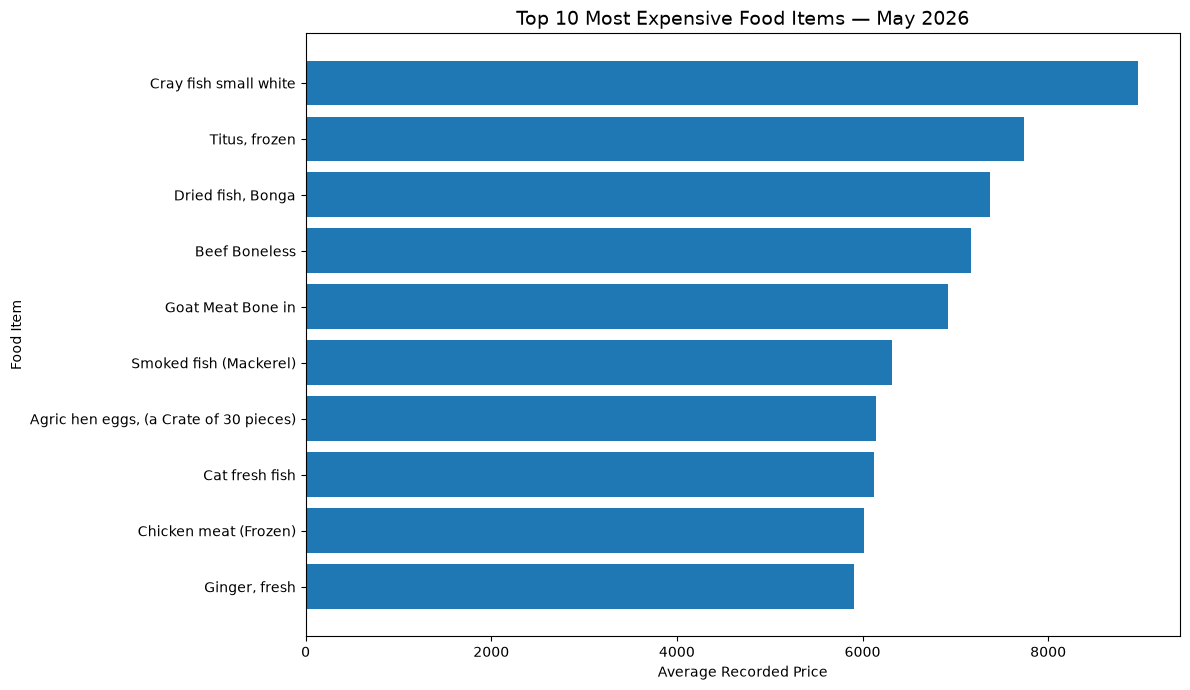

In [22]:
# STEP 12.3A: Visualise the 10 most expensive food items

import matplotlib.pyplot as plt

# Create a figure for the chart
plt.figure(figsize=(12, 7))

# Draw a horizontal bar chart
plt.barh(
    top_10_expensive["Item Label"],
    top_10_expensive["Average of May-26"]
)

# Put the most expensive item at the top
plt.gca().invert_yaxis()

# Add a title and axis labels
plt.title(
    "Top 10 Most Expensive Food Items — May 2026",
    fontsize=14
)

plt.xlabel("Average Recorded Price")
plt.ylabel("Food Item")

# Make the food names easier to read
plt.tight_layout()

# Display the chart
plt.show()

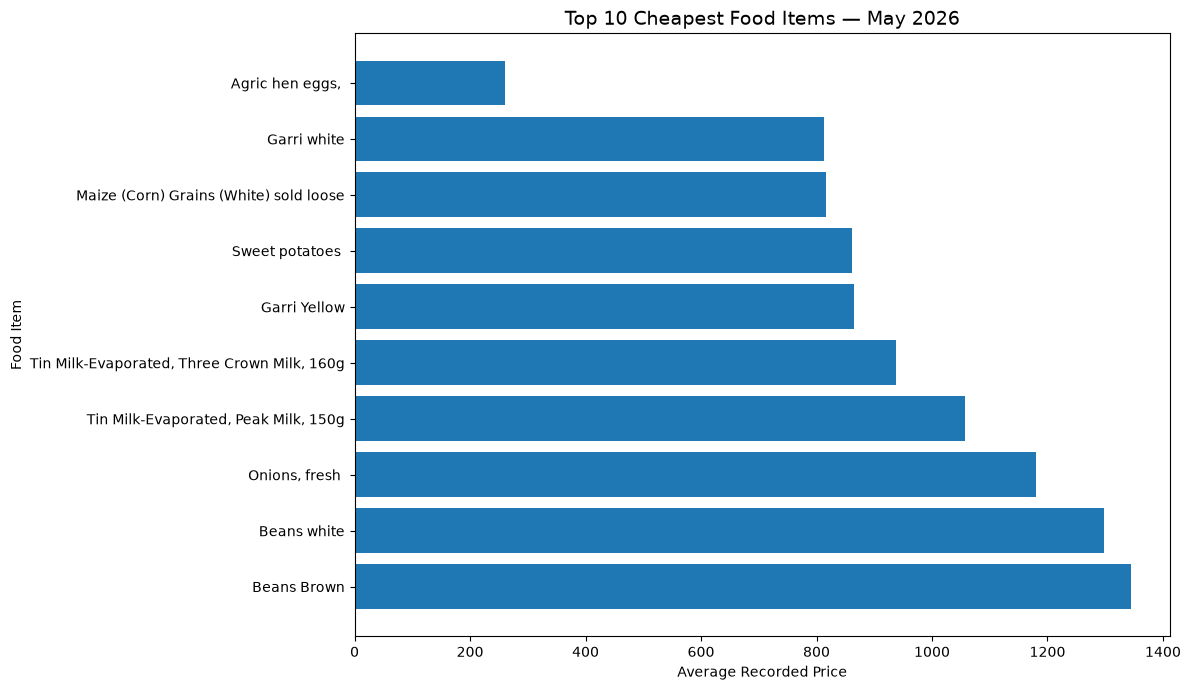

In [23]:
# STEP 12.3B: Visualise the 10 cheapest food items

# Create a figure for the chart
plt.figure(figsize=(12, 7))

# Draw a horizontal bar chart
plt.barh(
    top_10_cheapest["Item Label"],
    top_10_cheapest["Average of May-26"]
)

# Put the cheapest item at the top
plt.gca().invert_yaxis()

# Add a title and axis labels
plt.title(
    "Top 10 Cheapest Food Items — May 2026",
    fontsize=14
)

plt.xlabel("Average Recorded Price")
plt.ylabel("Food Item")

# Improve the layout
plt.tight_layout()

# Display the chart
plt.show()

In [24]:
# STEP 12.4: Compare the highest and lowest recorded food prices

# Select the column containing May 2026 average prices
current_price_column = "Average of May-26"

# Find the food item with the highest recorded price
most_expensive_item = food_clean.loc[
    food_clean[current_price_column].idxmax()
]

# Find the food item with the lowest recorded price
cheapest_item = food_clean.loc[
    food_clean[current_price_column].idxmin()
]

# Calculate the difference between the highest and lowest prices
price_range = (
    most_expensive_item[current_price_column]
    - cheapest_item[current_price_column]
)

# Calculate the ratio between the two prices
price_ratio = (
    most_expensive_item[current_price_column]
    / cheapest_item[current_price_column]
)

# Display the findings
print("FOOD PRICE COMPARISON — MAY 2026")
print("=" * 55)

print(
    f"Most expensive item: "
    f"{most_expensive_item['Item Label']}"
)

print(
    f"Highest recorded price: "
    f"{most_expensive_item[current_price_column]:,.2f}"
)

print()

print(
    f"Cheapest item: "
    f"{cheapest_item['Item Label']}"
)

print(
    f"Lowest recorded price: "
    f"{cheapest_item[current_price_column]:,.2f}"
)

print()

print(f"Difference between prices: {price_range:,.2f}")

print(
    f"Highest-to-lowest price ratio: "
    f"{price_ratio:.2f} times"
)

FOOD PRICE COMPARISON — MAY 2026
Most expensive item: Cray fish small white
Highest recorded price: 8,971.56

Cheapest item: Agric hen eggs, 
Lowest recorded price: 261.14

Difference between prices: 8,710.42
Highest-to-lowest price ratio: 34.36 times


In [25]:
# STEP 12.5A: Summarise month-to-month and year-to-year price changes

# Select the columns containing recorded price changes
change_columns = ["MoM", "YoY"]

# Calculate summary statistics for both columns
change_summary = food_clean[change_columns].describe().T

# Rename the summary columns to make them easier to understand
change_summary = change_summary.rename(
    columns={
        "count": "Number of Food Items",
        "mean": "Average Change (%)",
        "std": "Standard Deviation",
        "min": "Lowest Change (%)",
        "25%": "25th Percentile",
        "50%": "Median Change (%)",
        "75%": "75th Percentile",
        "max": "Highest Change (%)"
    }
)

# Display the results
print("SUMMARY OF FOOD PRICE CHANGES")
print("=" * 65)

display(change_summary.round(2))

SUMMARY OF FOOD PRICE CHANGES


,Number of Food Items,Average Change (%),Standard Deviation,Lowest Change (%),25th Percentile,Median Change (%),75th Percentile,Highest Change (%)
MoM,42.0,2.24,5.82,0.01,0.27,0.49,1.33,32.48
YoY,42.0,-3.58,15.97,-43.61,-8.18,0.72,6.22,27.36


In [26]:
# STEP 12.5B: Count food price increases and decreases

# --------------------------------------------------
# PART A: Analyse month-to-month changes
# --------------------------------------------------

# Count items whose prices increased from April to May 2026
mom_increases = (food_clean["MoM"] > 0).sum()

# Count items whose prices decreased from April to May 2026
mom_decreases = (food_clean["MoM"] < 0).sum()

# Count items whose prices did not change
mom_no_change = (food_clean["MoM"] == 0).sum()


# --------------------------------------------------
# PART B: Analyse year-to-year changes
# --------------------------------------------------

# Count items whose prices increased from May 2025 to May 2026
yoy_increases = (food_clean["YoY"] > 0).sum()

# Count items whose prices decreased over the year
yoy_decreases = (food_clean["YoY"] < 0).sum()

# Count items whose prices did not change
yoy_no_change = (food_clean["YoY"] == 0).sum()


# --------------------------------------------------
# PART C: Display the results
# --------------------------------------------------

print("FOOD PRICE MOVEMENT SUMMARY")
print("=" * 55)

print("\nMONTH-TO-MONTH: APRIL TO MAY 2026")
print("-" * 45)

print(f"Food items with price increases: {mom_increases}")
print(f"Food items with price decreases: {mom_decreases}")
print(f"Food items with no change: {mom_no_change}")
print(f"Total food items: {len(food_clean)}")

print("\nYEAR-TO-YEAR: MAY 2025 TO MAY 2026")
print("-" * 45)

print(f"Food items with price increases: {yoy_increases}")
print(f"Food items with price decreases: {yoy_decreases}")
print(f"Food items with no change: {yoy_no_change}")
print(f"Total food items: {len(food_clean)}")

FOOD PRICE MOVEMENT SUMMARY

MONTH-TO-MONTH: APRIL TO MAY 2026
---------------------------------------------
Food items with price increases: 42
Food items with price decreases: 0
Food items with no change: 0
Total food items: 42

YEAR-TO-YEAR: MAY 2025 TO MAY 2026
---------------------------------------------
Food items with price increases: 22
Food items with price decreases: 20
Food items with no change: 0
Total food items: 42


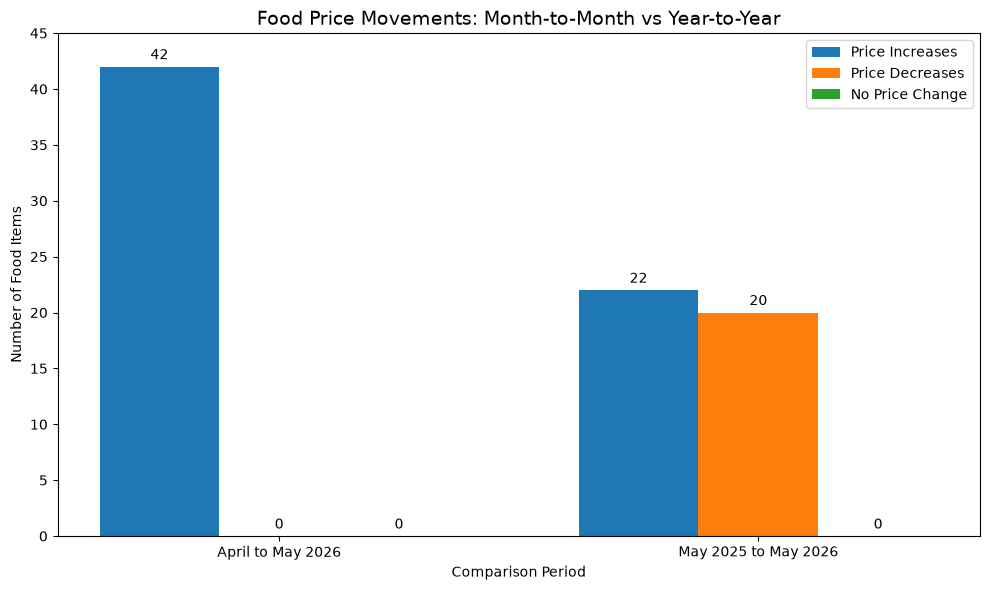

In [27]:
# STEP 12.5C: Visualise food price movements
# This chart compares price increases, decreases, and unchanged prices.

import matplotlib.pyplot as plt

# Create a summary of the results we calculated in Step 12.5B.
price_movement = {
    "Price Increases": [mom_increases, yoy_increases],
    "Price Decreases": [mom_decreases, yoy_decreases],
    "No Price Change": [mom_no_change, yoy_no_change]
}

# Define the two comparison periods.
periods = [
    "April to May 2026",
    "May 2025 to May 2026"
]

# Create a figure for the chart.
fig, ax = plt.subplots(figsize=(10, 6))

# Set the positions of the two periods.
positions = range(len(periods))

# Draw the bars for each type of price movement.
bar_width = 0.25

ax.bar(
    [position - bar_width for position in positions],
    price_movement["Price Increases"],
    width=bar_width,
    label="Price Increases"
)

ax.bar(
    positions,
    price_movement["Price Decreases"],
    width=bar_width,
    label="Price Decreases"
)

ax.bar(
    [position + bar_width for position in positions],
    price_movement["No Price Change"],
    width=bar_width,
    label="No Price Change"
)

# Add a descriptive title and axis labels.
ax.set_title(
    "Food Price Movements: Month-to-Month vs Year-to-Year",
    fontsize=14
)

ax.set_xlabel("Comparison Period")
ax.set_ylabel("Number of Food Items")

# Display the comparison periods beneath the bars.
ax.set_xticks(list(positions))
ax.set_xticklabels(periods)

# The chart should start at zero and end at 42 items.
ax.set_ylim(0, 45)

# Display the exact number above each bar.
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

# Display the legend and improve spacing.
ax.legend()
plt.tight_layout()

# Display the completed chart.
plt.show()

In [28]:
# STEP 12.6A: Summarise food prices across the six geopolitical zones

# List the six geopolitical zones in our dataset.
zones = [
    "NORTH CENTRAL",
    "NORTH EAST",
    "NORTH WEST",
    "SOUTH EAST",
    "SOUTH SOUTH",
    "SOUTH WEST"
]

# Calculate summary statistics for each zone.
# Each column represents a zone, while each row represents a food item.
regional_summary = zone_clean[zones].describe().T

# Give the statistics clear, readable names.
regional_summary = regional_summary.rename(columns={
    "count": "Number of Food Items",
    "mean": "Average Price",
    "std": "Standard Deviation",
    "min": "Minimum Price",
    "25%": "25th Percentile",
    "50%": "Median Price",
    "75%": "75th Percentile",
    "max": "Maximum Price"
})

# Display the results with two decimal places.
print("REGIONAL FOOD PRICE SUMMARY")
print("=" * 80)

display(regional_summary.round(2))

REGIONAL FOOD PRICE SUMMARY


,Number of Food Items,Average Price,Standard Deviation,Minimum Price,25th Percentile,Median Price,75th Percentile,Maximum Price
NORTH CENTRAL,42.0,3392.78,2516.55,258.26,1496.51,2386.94,5712.70,9030.44
NORTH EAST,42.0,3178.95,2438.45,271.84,1459.08,2104.03,4890.05,9011.92
NORTH WEST,42.0,2981.19,2195.71,256.78,1247.06,2060.40,4671.35,9246.85
SOUTH EAST,42.0,3705.36,2758.24,264.04,1683.50,2493.07,6288.85,9549.64
SOUTH SOUTH,42.0,3484.19,2248.13,260.94,1748.23,2603.32,5729.99,7718.13
SOUTH WEST,42.0,3428.13,2384.10,256.67,1745.67,2512.62,5728.66,9787.23


In [29]:
# STEP 12.6B: Verify and display the regional summary correctly

# Select the six geopolitical zones.
zones = [
    "NORTH CENTRAL",
    "NORTH EAST",
    "NORTH WEST",
    "SOUTH EAST",
    "SOUTH SOUTH",
    "SOUTH WEST"
]

# Recalculate the summary statistics directly from the cleaned dataset.
regional_summary = zone_clean[zones].describe().T

# Rename the columns to make the table easy to understand.
regional_summary = regional_summary.rename(columns={
    "count": "Number of Food Items",
    "mean": "Average Price",
    "std": "Standard Deviation",
    "min": "Minimum Price",
    "25%": "25th Percentile",
    "50%": "Median Price",
    "75%": "75th Percentile",
    "max": "Maximum Price"
})

# Arrange the columns in a clear, logical order.
regional_summary = regional_summary[
    [
        "Number of Food Items",
        "Average Price",
        "Standard Deviation",
        "Minimum Price",
        "25th Percentile",
        "Median Price",
        "75th Percentile",
        "Maximum Price"
    ]
]

# Display the verified results.
print("VERIFIED REGIONAL FOOD PRICE SUMMARY")
print("=" * 60)

display(regional_summary.round(2))

# Identify the zones with the highest and lowest average prices.
highest_average_zone = regional_summary["Average Price"].idxmax()
lowest_average_zone = regional_summary["Average Price"].idxmin()

print("\nREGIONAL COMPARISON")
print("-" * 40)

print(
    f"Highest average price: {highest_average_zone} "
    f"({regional_summary.loc[highest_average_zone, 'Average Price']:,.2f})"
)

print(
    f"Lowest average price: {lowest_average_zone} "
    f"({regional_summary.loc[lowest_average_zone, 'Average Price']:,.2f})"
)

VERIFIED REGIONAL FOOD PRICE SUMMARY


,Number of Food Items,Average Price,Standard Deviation,Minimum Price,25th Percentile,Median Price,75th Percentile,Maximum Price
NORTH CENTRAL,42.0,3392.78,2516.55,258.26,1496.51,2386.94,5712.70,9030.44
NORTH EAST,42.0,3178.95,2438.45,271.84,1459.08,2104.03,4890.05,9011.92
NORTH WEST,42.0,2981.19,2195.71,256.78,1247.06,2060.40,4671.35,9246.85
SOUTH EAST,42.0,3705.36,2758.24,264.04,1683.50,2493.07,6288.85,9549.64
SOUTH SOUTH,42.0,3484.19,2248.13,260.94,1748.23,2603.32,5729.99,7718.13
SOUTH WEST,42.0,3428.13,2384.10,256.67,1745.67,2512.62,5728.66,9787.23



REGIONAL COMPARISON
----------------------------------------
Highest average price: SOUTH EAST (3,705.36)
Lowest average price: NORTH WEST (2,981.19)


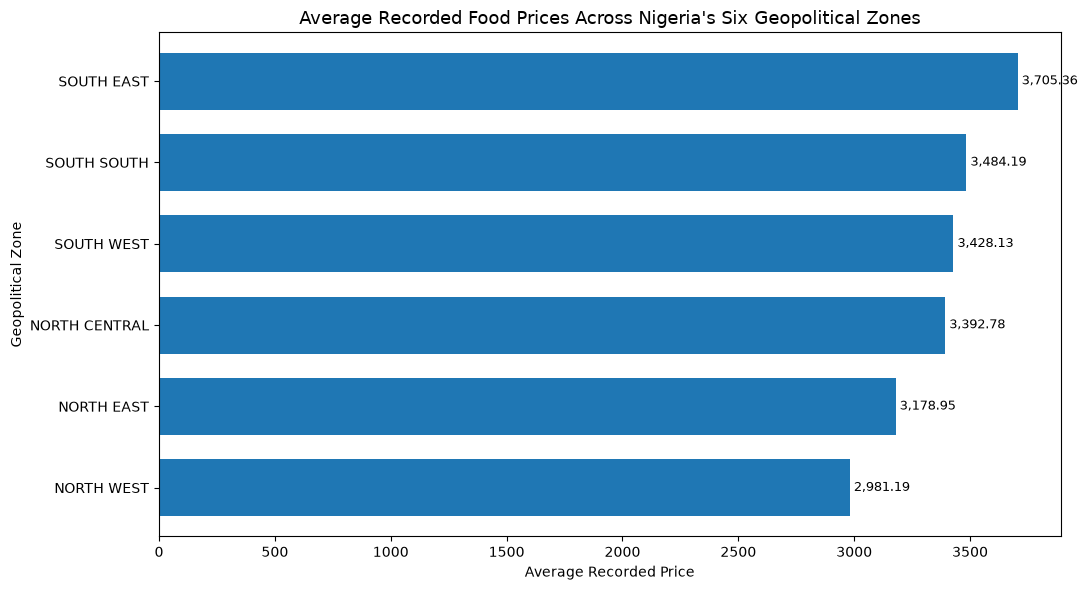

In [30]:
# STEP 12.6C: Compare average food prices across Nigeria's six zones

import matplotlib.pyplot as plt

# Calculate the average recorded price for each geopolitical zone.
average_prices = zone_clean[zones].mean().sort_values(ascending=True)

# Create a figure for the chart.
plt.figure(figsize=(11, 6))

# Draw a horizontal bar chart.
average_prices.plot(
    kind="barh",
    width=0.7
)

# Add a clear title and axis labels.
plt.title(
    "Average Recorded Food Prices Across Nigeria's Six Geopolitical Zones",
    fontsize=13
)

plt.xlabel("Average Recorded Price")
plt.ylabel("Geopolitical Zone")

# Display the exact average price beside each bar.
for position, value in enumerate(average_prices):
    plt.text(
        value,
        position,
        f" {value:,.2f}",
        va="center",
        fontsize=9
    )

# Improve the spacing and display the chart.
plt.tight_layout()
plt.show()

In [31]:
# STEP 12.6D: Find the five most expensive and cheapest items in each zone

# We will examine one geopolitical zone at a time.
for zone in zones:

    print("\n" + "=" * 80)
    print(f"FOOD PRICE ANALYSIS: {zone}")
    print("=" * 80)

    # --------------------------------------------------
    # PART A: Five most expensive food items
    # --------------------------------------------------

    # Sort food items from highest to lowest price.
    most_expensive = (
        zone_clean[["Item Label", zone]]
        .sort_values(by=zone, ascending=False)
        .head(5)
    )

    print("\nFIVE MOST EXPENSIVE FOOD ITEMS")
    display(most_expensive.reset_index(drop=True).round(2))

    # --------------------------------------------------
    # PART B: Five cheapest food items
    # --------------------------------------------------

    # Sort food items from lowest to highest price.
    cheapest = (
        zone_clean[["Item Label", zone]]
        .sort_values(by=zone, ascending=True)
        .head(5)
    )

    print("\nFIVE CHEAPEST FOOD ITEMS")
    display(cheapest.reset_index(drop=True).round(2))


FOOD PRICE ANALYSIS: NORTH CENTRAL

FIVE MOST EXPENSIVE FOOD ITEMS


,Item Label,NORTH CENTRAL
0,Cray fish small white,9030.44
1,"Titus, frozen",8111.58
2,"Dried fish, Bonga",7816.03
3,"Mackerel, Frozen",7642.10
4,Beef Boneless,6999.35



FIVE CHEAPEST FOOD ITEMS


,Item Label,NORTH CENTRAL
0,"Agric hen eggs,",258.26
1,Garri white,676.21
2,Sweet potatoes,694.66
3,Maize (Corn) Grains (White) sold loose,703.59
4,Garri Yellow,812.96



FOOD PRICE ANALYSIS: NORTH EAST

FIVE MOST EXPENSIVE FOOD ITEMS


...

,Item Label,SOUTH SOUTH
0,"Agric hen eggs,",260.94
1,Garri Yellow,904.14
2,Garri white,944.01
3,"Tin Milk-Evaporated, Three Crown Milk, 160g",994.24
4,Maize (Corn) Grains (White) sold loose,1066.89



FOOD PRICE ANALYSIS: SOUTH WEST

FIVE MOST EXPENSIVE FOOD ITEMS


,Item Label,SOUTH WEST
0,Cray fish small white,9787.23
1,"Titus, frozen",7416.27
2,Goat Meat Bone in,7228.60
3,"Ginger, fresh",6969.86
4,"Dried fish, Bonga",6901.56



FIVE CHEAPEST FOOD ITEMS


,Item Label,SOUTH WEST
0,"Agric hen eggs,",256.67
1,Sweet potatoes,738.61
2,Maize (Corn) Grains (White) sold loose,804.83
3,Garri white,823.46
4,"Tin Milk-Evaporated, Three Crown Milk, 160g",914.42


In [32]:
# STEP 12.7A: Compare the price of every food item across the six zones

# Select the six geopolitical zone columns.
zones = [
    "NORTH CENTRAL",
    "NORTH EAST",
    "NORTH WEST",
    "SOUTH EAST",
    "SOUTH SOUTH",
    "SOUTH WEST"
]

# Create a copy so our original cleaned dataset remains unchanged.
regional_comparison = zone_clean[["Item Label"] + zones].copy()

# Identify the zone with the highest recorded price for each food item.
regional_comparison["Highest Price Zone"] = (
    regional_comparison[zones].idxmax(axis=1)
)

# Record the highest price for each food item.
regional_comparison["Highest Recorded Price"] = (
    regional_comparison[zones].max(axis=1)
)

# Identify the zone with the lowest recorded price for each food item.
regional_comparison["Lowest Price Zone"] = (
    regional_comparison[zones].idxmin(axis=1)
)

# Record the lowest price for each food item.
regional_comparison["Lowest Recorded Price"] = (
    regional_comparison[zones].min(axis=1)
)

# Calculate the difference between the highest and lowest recorded prices.
regional_comparison["Price Difference"] = (
    regional_comparison["Highest Recorded Price"]
    - regional_comparison["Lowest Recorded Price"]
)

# Display the comparison results.
print("FOOD PRICE DIFFERENCES ACROSS NIGERIA'S SIX ZONES")
print("=" * 80)

display(
    regional_comparison[
        [
            "Item Label",
            "Highest Price Zone",
            "Highest Recorded Price",
            "Lowest Price Zone",
            "Lowest Recorded Price",
            "Price Difference"
        ]
    ].round(2)
)

FOOD PRICE DIFFERENCES ACROSS NIGERIA'S SIX ZONES


,Item Label,Highest Price Zone,Highest Recorded Price,Lowest Price Zone,Lowest Recorded Price,Price Difference
0,"Agric hen eggs,",NORTH EAST,271.84,SOUTH WEST,256.67,15.17
1,"Agric hen eggs, (a Crate of 30 pieces)",SOUTH EAST,6549.86,NORTH WEST,5932.19,617.67
2,Beans Brown,SOUTH WEST,1790.71,NORTH EAST,876.46,914.25
3,Beans white,SOUTH SOUTH,1741.42,NORTH EAST,835.98,905.44
4,Beef Boneless,SOUTH EAST,8420.68,NORTH WEST,6186.27,2234.41
5,"Bread (sliced), 450g",NORTH WEST,1773.54,NORTH EAST,1485.70,287.84
6,"Bread (unsliced), 450g",NORTH WEST,1771.81,SOUTH WEST,1410.21,361.61
7,"Carrots, fresh",SOUTH SOUTH,2612.10,NORTH EAST,1601.54,1010.56
8,Cat fresh fish,SOUTH EAST,6969.25,NORTH WEST,4941.61,2027.63
9,Chicken feet,SOUTH WEST,4946.41,NORTH WEST,2804.89,2141.52


In [33]:
# STEP 12.7B: Identify food items with the largest regional price differences

# Select the columns needed for our comparison.
comparison_columns = [
    "Item Label",
    "Highest Price Zone",
    "Highest Recorded Price",
    "Lowest Price Zone",
    "Lowest Recorded Price",
    "Price Difference"
]

# Create a table containing the five largest price differences.
largest_differences = (
    regional_comparison[comparison_columns]
    .sort_values(by="Price Difference", ascending=False)
    .head(5)
    .reset_index(drop=True)
)

# Create a table containing the five smallest price differences.
smallest_differences = (
    regional_comparison[comparison_columns]
    .sort_values(by="Price Difference", ascending=True)
    .head(5)
    .reset_index(drop=True)
)

# Display the five items with the largest differences.
print("FIVE FOOD ITEMS WITH THE LARGEST REGIONAL PRICE DIFFERENCES")
print("=" * 80)

display(largest_differences.round(2))

# Display the five items with the smallest differences.
print("\nFIVE FOOD ITEMS WITH THE SMALLEST REGIONAL PRICE DIFFERENCES")
print("=" * 80)

display(smallest_differences.round(2))

FIVE FOOD ITEMS WITH THE LARGEST REGIONAL PRICE DIFFERENCES


,Item Label,Highest Price Zone,Highest Recorded Price,Lowest Price Zone,Lowest Recorded Price,Price Difference
0,"Dried fish, Bonga",SOUTH EAST,9549.64,NORTH WEST,6001.13,3548.51
1,Chicken meat (Frozen),SOUTH EAST,8237.58,NORTH EAST,5021.63,3215.94
2,"Mackerel, Frozen",NORTH CENTRAL,7642.10,NORTH WEST,4565.35,3076.75
3,Goat Meat Bone in,SOUTH EAST,8599.13,NORTH CENTRAL,5722.02,2877.11
4,Smoked fish,SOUTH EAST,7415.55,NORTH WEST,4825.07,2590.48



FIVE FOOD ITEMS WITH THE SMALLEST REGIONAL PRICE DIFFERENCES


,Item Label,Highest Price Zone,Highest Recorded Price,Lowest Price Zone,Lowest Recorded Price,Price Difference
0,"Agric hen eggs,",NORTH EAST,271.84,SOUTH WEST,256.67,15.17
1,"Tin Milk-Evaporated, Three Crown Milk, 160g",NORTH EAST,1042.78,NORTH CENTRAL,870.91,171.87
2,"Tin Milk-Evaporated, Peak Milk, 150g",SOUTH SOUTH,1135.45,NORTH WEST,933.53,201.92
3,Garri Yellow,SOUTH EAST,998.69,NORTH EAST,748.73,249.96
4,Garri white,SOUTH EAST,947.08,NORTH CENTRAL,676.21,270.86


In [34]:
# STEP 12.7C: Calculate percentage differences in regional food prices

# Work with a copy so we preserve the original comparison table.
regional_percentage_comparison = regional_comparison.copy()

# Calculate the percentage difference relative to the lowest recorded price.
regional_percentage_comparison["Price Difference (%)"] = (
    regional_percentage_comparison["Price Difference"]
    / regional_percentage_comparison["Lowest Recorded Price"]
) * 100

# Select the columns needed for the analysis.
percentage_columns = [
    "Item Label",
    "Highest Price Zone",
    "Highest Recorded Price",
    "Lowest Price Zone",
    "Lowest Recorded Price",
    "Price Difference",
    "Price Difference (%)"
]

# Identify the five items with the largest percentage differences.
largest_percentage_differences = (
    regional_percentage_comparison[percentage_columns]
    .sort_values(by="Price Difference (%)", ascending=False)
    .head(5)
    .reset_index(drop=True)
)

# Display the results.
print("FIVE FOOD ITEMS WITH THE LARGEST PERCENTAGE PRICE DIFFERENCES")
print("=" * 85)

display(largest_percentage_differences.round(2))

FIVE FOOD ITEMS WITH THE LARGEST PERCENTAGE PRICE DIFFERENCES


,Item Label,Highest Price Zone,Highest Recorded Price,Lowest Price Zone,Lowest Recorded Price,Price Difference,Price Difference (%)
0,Maize (Corn) Grains (White) sold loose,SOUTH SOUTH,1066.89,NORTH EAST,507.47,559.42,110.24
1,Beans white,SOUTH SOUTH,1741.42,NORTH EAST,835.98,905.44,108.31
2,Beans Brown,SOUTH WEST,1790.71,NORTH EAST,876.46,914.25,104.31
3,Irish Potatoe,SOUTH SOUTH,2754.76,NORTH WEST,1441.06,1313.70,91.16
4,"Onions, fresh",SOUTH EAST,1755.96,NORTH CENTRAL,931.15,824.81,88.58


In [36]:

# STEP 12.7D: Summarise percentage price differences across all food items

# Calculate the average percentage difference
average_percentage_difference = (
    regional_percentage_comparison["Price Difference (%)"].mean()
)

# Calculate the median percentage difference
median_percentage_difference = (
    regional_percentage_comparison["Price Difference (%)"].median()
)

# Identify the food item with the largest percentage difference
largest_difference_item = regional_percentage_comparison.loc[
    regional_percentage_comparison["Price Difference (%)"].idxmax()
]

# Identify the food item with the smallest percentage difference
smallest_difference_item = regional_percentage_comparison.loc[
    regional_percentage_comparison["Price Difference (%)"].idxmin()
]

# Display the findings clearly
print("REGIONAL FOOD PRICE DIFFERENCE SUMMARY")
print("=" * 55)

print(
    f"Number of food items analysed: "
    f"{len(regional_percentage_comparison)}"
)

print(
    f"Average percentage price difference: "
    f"{average_percentage_difference:.2f}%"
)

print(
    f"Median percentage price difference: "
    f"{median_percentage_difference:.2f}%"
)

print("\nLARGEST PERCENTAGE DIFFERENCE")
print("-" * 35)
print(f"Food item: {largest_difference_item['Item Label']}")
print(
    f"Percentage difference: "
    f"{largest_difference_item['Price Difference (%)']:.2f}%"
)

print("\nSMALLEST PERCENTAGE DIFFERENCE")
print("-" * 35)
print(f"Food item: {smallest_difference_item['Item Label']}")
print(
    f"Percentage difference: "
    f"{smallest_difference_item['Price Difference (%)']:.2f}%"
)



REGIONAL FOOD PRICE DIFFERENCE SUMMARY
Number of food items analysed: 42
Average percentage price difference: 45.72%
Median percentage price difference: 40.54%

LARGEST PERCENTAGE DIFFERENCE
-----------------------------------
Food item: Maize (Corn) Grains (White) sold loose
Percentage difference: 110.24%

SMALLEST PERCENTAGE DIFFERENCE
-----------------------------------
Food item: Agric hen eggs,
Percentage difference: 5.91%


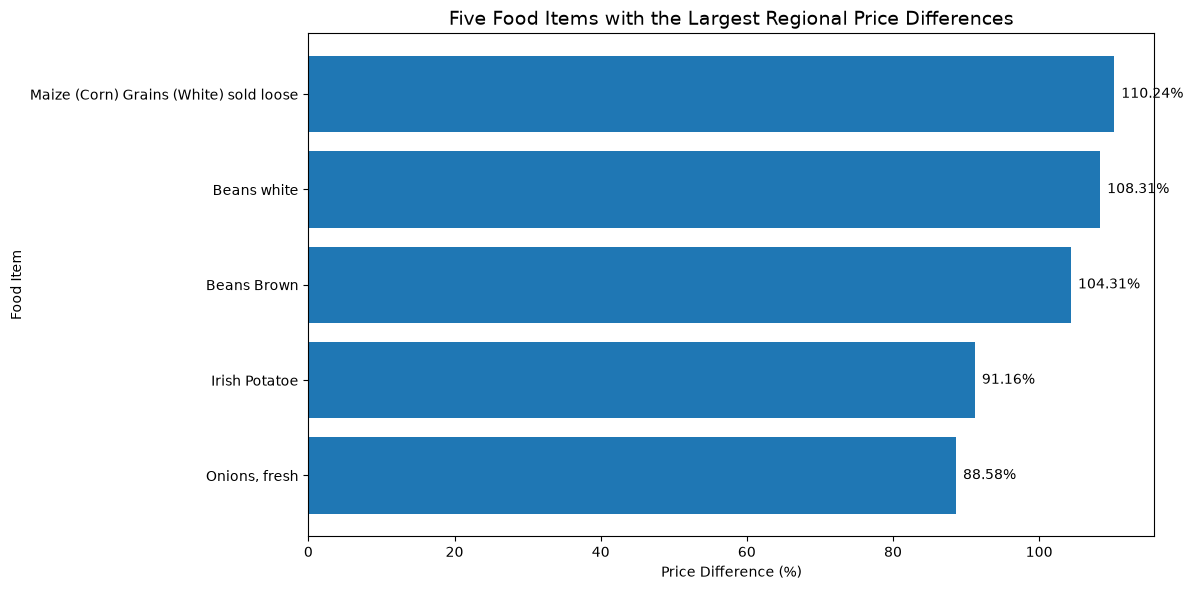

In [37]:

# STEP 12.8A: Visualise the five largest regional price differences

import matplotlib.pyplot as plt

# Select the five food items with the largest percentage differences
top_5_regional_differences = (
    regional_percentage_comparison
    .sort_values(by="Price Difference (%)", ascending=False)
    .head(5)
    .sort_values(by="Price Difference (%)", ascending=True)
)

# Create the chart
plt.figure(figsize=(12, 6))

plt.barh(
    top_5_regional_differences["Item Label"],
    top_5_regional_differences["Price Difference (%)"]
)

# Add a title and labels
plt.title(
    "Five Food Items with the Largest Regional Price Differences",
    fontsize=14
)

plt.xlabel("Price Difference (%)")
plt.ylabel("Food Item")

# Add percentage values beside each bar
for position, value in enumerate(
    top_5_regional_differences["Price Difference (%)"]
):
    plt.text(value + 1, position, f"{value:.2f}%", va="center")

# Improve spacing and display the chart
plt.tight_layout()
plt.show()


In [38]:

# STEP 12.8B: Count how often each zone has the highest or lowest price

# Count how often each zone records the highest price
highest_price_counts = (
    regional_comparison["Highest Price Zone"]
    .value_counts()
)

# Count how often each zone records the lowest price
lowest_price_counts = (
    regional_comparison["Lowest Price Zone"]
    .value_counts()
)

# Combine both counts into one summary table
regional_frequency = pd.DataFrame({
    "Times Highest Price": highest_price_counts,
    "Times Lowest Price": lowest_price_counts
}).fillna(0).astype(int)

# Ensure every geopolitical zone appears in the table
zones = [
    "NORTH CENTRAL",
    "NORTH EAST",
    "NORTH WEST",
    "SOUTH EAST",
    "SOUTH SOUTH",
    "SOUTH WEST"
]

regional_frequency = regional_frequency.reindex(
    zones,
    fill_value=0
)

# Calculate the percentage of food items for each ranking
regional_frequency["Highest Price (%)"] = (
    regional_frequency["Times Highest Price"] / len(regional_comparison) * 100
)

regional_frequency["Lowest Price (%)"] = (
    regional_frequency["Times Lowest Price"] / len(regional_comparison) * 100
)

# Display the results
print("REGIONAL PRICE RANKING FREQUENCY")
print("=" * 65)

display(regional_frequency.round(2))

REGIONAL PRICE RANKING FREQUENCY


,Times Highest Price,Times Lowest Price,Highest Price (%),Lowest Price (%)
NORTH CENTRAL,7,7,16.67,16.67
NORTH EAST,2,14,4.76,33.33
NORTH WEST,2,15,4.76,35.71
SOUTH EAST,15,2,35.71,4.76
SOUTH SOUTH,10,1,23.81,2.38
SOUTH WEST,6,3,14.29,7.14


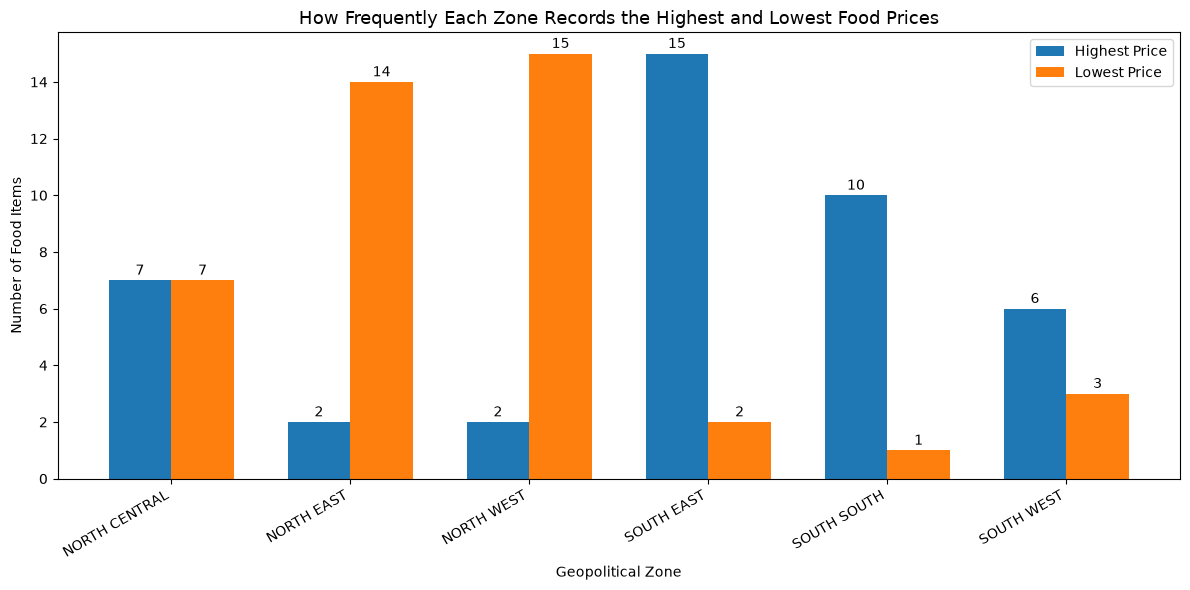

In [39]:

# STEP 12.8C: Compare the frequency of highest and lowest regional prices

import matplotlib.pyplot as plt
import numpy as np

# Get the names of the six geopolitical zones
zone_names = regional_frequency.index.tolist()

# Get the counts for highest and lowest prices
highest_counts = regional_frequency["Times Highest Price"]
lowest_counts = regional_frequency["Times Lowest Price"]

# Set the positions of the bars
positions = np.arange(len(zone_names))
bar_width = 0.35

# Create the chart
plt.figure(figsize=(12, 6))

# Draw bars for highest and lowest prices
plt.bar(
    positions - bar_width / 2,
    highest_counts,
    bar_width,
    label="Highest Price"
)

plt.bar(
    positions + bar_width / 2,
    lowest_counts,
    bar_width,
    label="Lowest Price"
)

# Add titles and labels
plt.title(
    "How Frequently Each Zone Records the Highest and Lowest Food Prices",
    fontsize=13
)

plt.xlabel("Geopolitical Zone")
plt.ylabel("Number of Food Items")

# Label the horizontal axis
plt.xticks(positions, zone_names, rotation=30, ha="right")

# Display the values above each bar
for position, value in zip(positions - bar_width / 2, highest_counts):
    plt.text(position, value + 0.2, str(value), ha="center")

for position, value in zip(positions + bar_width / 2, lowest_counts):
    plt.text(position, value + 0.2, str(value), ha="center")

# Display the legend and improve spacing
plt.legend()
plt.tight_layout()
plt.show()



In [40]:

# STEP 12.9A: Measure how much each food item's price varies across zones

# List the six geopolitical zones
zone_columns = [
    "NORTH CENTRAL",
    "NORTH EAST",
    "NORTH WEST",
    "SOUTH EAST",
    "SOUTH SOUTH",
    "SOUTH WEST"
]

# Create a separate DataFrame for the regional price calculations
regional_variability = zone_clean[["Item Label"] + zone_columns].copy()

# Calculate the average price for each food item across the six zones
regional_variability["Average Regional Price"] = (
    regional_variability[zone_columns].mean(axis=1)
)

# Calculate the standard deviation across the six zones
regional_variability["Regional Price Std Dev"] = (
    regional_variability[zone_columns].std(axis=1)
)

# Calculate the difference between the highest and lowest regional prices
regional_variability["Regional Price Range"] = (
    regional_variability[zone_columns].max(axis=1)
    - regional_variability[zone_columns].min(axis=1)
)

# Display the five food items with the greatest standard deviation
most_variable_foods = (
    regional_variability
    .sort_values(
        by="Regional Price Std Dev",
        ascending=False
    )
    .head(5)
    .reset_index(drop=True)
)

print("FIVE FOOD ITEMS WITH THE GREATEST REGIONAL PRICE VARIABILITY")
print("=" * 75)

display(
    most_variable_foods[
        [
            "Item Label",
            "Average Regional Price",
            "Regional Price Std Dev",
            "Regional Price Range"
        ]
    ].round(2)
)


FIVE FOOD ITEMS WITH THE GREATEST REGIONAL PRICE VARIABILITY


,Item Label,Average Regional Price,Regional Price Std Dev,Regional Price Range
0,"Dried fish, Bonga",7455.32,1231.02,3548.51
1,Chicken meat (Frozen),6085.06,1143.49,3215.94
2,"Mackerel, Frozen",5830.12,1043.27,3076.75
3,Goat Meat Bone in,7019.03,974.25,2877.11
4,"Ginger, fresh",5941.49,891.08,2474.57


In [41]:

# STEP 12.9B: Compare relative price variability across food items

# Calculate the coefficient of variation as a percentage
regional_variability["Price CV (%)"] = (
    regional_variability["Regional Price Std Dev"]
    / regional_variability["Average Regional Price"]
) * 100

# Select the five food items with the highest coefficient of variation
highest_relative_variability = (
    regional_variability
    .sort_values(
        by="Price CV (%)",
        ascending=False
    )
    .head(5)
    .reset_index(drop=True)
)

# Display the results
print("FIVE FOOD ITEMS WITH THE HIGHEST RELATIVE REGIONAL PRICE VARIABILITY")
print("=" * 80)

display(
    highest_relative_variability[
        [
            "Item Label",
            "Average Regional Price",
            "Regional Price Std Dev",
            "Price CV (%)"
        ]
    ].round(2)
)


FIVE FOOD ITEMS WITH THE HIGHEST RELATIVE REGIONAL PRICE VARIABILITY


,Item Label,Average Regional Price,Regional Price Std Dev,Price CV (%)
0,Beans Brown,1367.84,420.25,30.72
1,Beans white,1319.68,398.93,30.23
2,Sweet potatoes,872.53,227.74,26.10
3,Irish Potatoe,2144.29,539.89,25.18
4,"Onions, fresh",1207.51,293.11,24.27


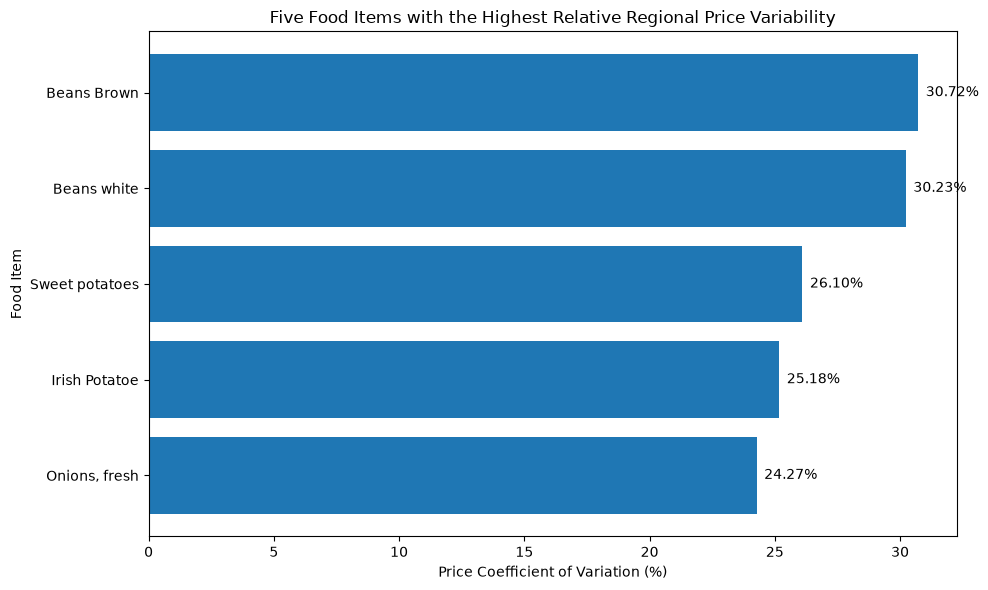

In [42]:
# STEP 12.9C: Visualise the five foods with the highest relative price variability

import matplotlib.pyplot as plt

# Sort the five food items from lowest to highest CV
# This makes the horizontal bar chart easier to read.
chart_data = highest_relative_variability.sort_values(
    by="Price CV (%)",
    ascending=True
)

# Create the figure
plt.figure(figsize=(10, 6))

# Draw the horizontal bar chart
plt.barh(
    chart_data["Item Label"],
    chart_data["Price CV (%)"]
)

# Add a title and axis labels
plt.title(
    "Five Food Items with the Highest Relative Regional Price Variability"
)

plt.xlabel("Price Coefficient of Variation (%)")
plt.ylabel("Food Item")

# Display the percentage at the end of each bar
for position, value in enumerate(chart_data["Price CV (%)"]):
    plt.text(
        value + 0.3,
        position,
        f"{value:.2f}%",
        va="center"
    )

# Improve spacing and display the chart
plt.tight_layout()
plt.show()

In [43]:
# STEP 12.10A: Identify foods with the lowest relative regional price variability

# Sort the food items by their coefficient of variation,
# starting with the lowest percentage.
lowest_relative_variability = (
    regional_variability
    .sort_values(
        by="Price CV (%)",
        ascending=True
    )
    .head(5)
    .reset_index(drop=True)
)

# Display the results in a readable table.
print("FIVE FOOD ITEMS WITH THE LOWEST RELATIVE REGIONAL PRICE VARIABILITY")
print("=" * 85)

display(
    lowest_relative_variability[
        [
            "Item Label",
            "Average Regional Price",
            "Regional Price Std Dev",
            "Price CV (%)"
        ]
    ].round(2)
)

FIVE FOOD ITEMS WITH THE LOWEST RELATIVE REGIONAL PRICE VARIABILITY


,Item Label,Average Regional Price,Regional Price Std Dev,Price CV (%)
0,"Agric hen eggs,",261.42,5.83,2.23
1,"Titus, frozen",7722.25,290.39,3.76
2,"Agric hen eggs, (a Crate of 30 pieces)",6170.76,244.85,3.97
3,"Palm oil, 75cl",2390.08,119.42,5.00
4,"Wheat Flour, Prepacked (2kg)",3663.79,183.26,5.00


In [44]:
# STEP 12.10B: Compare the highest and lowest relative price variability

# Select the five foods with the highest price variability.
highest_cv = (
    regional_variability
    .sort_values(by="Price CV (%)", ascending=False)
    .head(5)
    .copy()
)

# Select the five foods with the lowest price variability.
lowest_cv = (
    regional_variability
    .sort_values(by="Price CV (%)", ascending=True)
    .head(5)
    .copy()
)

# Add a label to identify each group.
highest_cv["Variability Group"] = "Highest variability"
lowest_cv["Variability Group"] = "Lowest variability"

# Combine both groups into one table.
variability_comparison = pd.concat(
    [highest_cv, lowest_cv],
    ignore_index=True
)

# Display the comparison.
print("COMPARISON OF REGIONAL PRICE VARIABILITY")
print("=" * 75)

display(
    variability_comparison[
        [
            "Item Label",
            "Average Regional Price",
            "Regional Price Std Dev",
            "Price CV (%)",
            "Variability Group"
        ]
    ].round(2)
)

COMPARISON OF REGIONAL PRICE VARIABILITY


,Item Label,Average Regional Price,Regional Price Std Dev,Price CV (%),Variability Group
0,Beans Brown,1367.84,420.25,30.72,Highest variability
1,Beans white,1319.68,398.93,30.23,Highest variability
2,Sweet potatoes,872.53,227.74,26.10,Highest variability
3,Irish Potatoe,2144.29,539.89,25.18,Highest variability
4,"Onions, fresh",1207.51,293.11,24.27,Highest variability
5,"Agric hen eggs,",261.42,5.83,2.23,Lowest variability
6,"Titus, frozen",7722.25,290.39,3.76,Lowest variability
7,"Agric hen eggs, (a Crate of 30 pieces)",6170.76,244.85,3.97,Lowest variability
8,"Palm oil, 75cl",2390.08,119.42,5.00,Lowest variability
9,"Wheat Flour, Prepacked (2kg)",3663.79,183.26,5.00,Lowest variability
